# 06 — EDA ampliado y preparación para modelamiento

**CRISP-DM:** *Data Understanding* (parte A) y *Data Preparation* (parte B), ahora sobre
la muestra ampliada de EP2. El EDA de EP1 (`02_exploracion_waymo.ipynb`) cubrió solo 4
segmentos de contraste; acá se repite con los **41 segmentos supervisados** que salen del
pipeline `ingesta_waymo` (más los 5 de lluvia, solo para comparar distribuciones).

**Entradas (catálogo de Kedro):** `waymo_supervisado` (frames etiquetados de los 41
segmentos), `waymo_con_target` (46 segmentos, con los 5 de lluvia sin target) y
`reporte_filtro_frames`.

**Salidas:** `data/05_model_input/train.parquet`, `test.parquet`, `config_features.json` y
`split_segmentos.csv`; gráficos en `images/`.

## Preguntas que responde el EDA

1. ¿Qué calidad tienen los datos y cuánto cambió con el filtro de frames?
2. ¿Cómo se comporta el target (`tiene_camara`) por segmento, ubicación, hora y clase?
3. ¿Qué variables parecen informativas? En particular: la cámara solo cubre parte del
   entorno del auto, así que **la posición del objeto (distancia y ángulo)** debería
   importar más que el tamaño o los puntos LiDAR (hipótesis que ya se había descartado
   para `num_lidar_points` en EP1).
4. ¿Qué diferencias hay entre lluvia y soleado en las variables de entrada?

## Decisiones de diseño que se justifican acá

- `weather`, `location`, `time_of_day` **no entran como variables del modelo**: se usan
  solo para evaluar equidad (ver sección B.1).
- El split train/test es **por segmento**, nunca por fila (ver sección B.3).
- El test **no se toca** hasta la evaluación final (notebook 10).

## Sección 0 — Configuración y carga

Funciona dentro de `kedro jupyter notebook` (usa `catalog` y `context`). Si se ejecuta
fuera de Kedro, lee los archivos directamente desde `data/`.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

# Raiz del proyecto: con Kedro viene en `context`; si no, se busca hacia arriba.
try:
    RAIZ = Path(context.project_path)
except NameError:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists())

RUTA_IMAGENES = RAIZ / "images"
RUTA_MODEL_INPUT = RAIZ / "data" / "05_model_input"
RUTA_IMAGENES.mkdir(exist_ok=True)
RUTA_MODEL_INPUT.mkdir(parents=True, exist_ok=True)


def cargar(nombre, ruta_relativa):
    # Carga desde el catalogo de Kedro; si no hay catalogo, lee el archivo directo.
    try:
        return catalog.load(nombre)
    except NameError:
        ruta = RAIZ / ruta_relativa
        return pd.read_csv(ruta) if ruta.suffix == ".csv" else pd.read_parquet(ruta)


def guardar_fig(fig, nombre):
    fig.savefig(RUTA_IMAGENES / f"{nombre}.png", dpi=150, bbox_inches="tight")


def preparar_columnas(d):
    # Variables geometricas derivadas de la posicion/orientacion del objeto. Ninguna usa la camara.
    d = d.copy()
    d["azimut_deg"] = np.degrees(np.arctan2(d["box_center_y"], d["box_center_x"]))   # 0 = frente del auto
    d["azimut_abs_deg"] = d["azimut_deg"].abs()                                      # 180 = detras
    d["heading_sin"] = np.sin(d["[LiDARBoxComponent].box.heading"])
    d["heading_cos"] = np.cos(d["[LiDARBoxComponent].box.heading"])
    d["num_top_lidar_points"] = d["[LiDARBoxComponent].num_top_lidar_points_in_box"]
    return d


df = preparar_columnas(cargar("waymo_supervisado", "data/02_intermediate/waymo_supervisado.parquet"))
completo = preparar_columnas(cargar("waymo_con_target", "data/02_intermediate/waymo_con_target.parquet"))
reporte_frames = cargar("reporte_filtro_frames", "data/08_reporting/reporte_filtro_frames.csv")

print(f"Raiz del proyecto: {RAIZ}")
print(f"waymo_supervisado: {len(df):,} filas | {df['segment_id'].nunique()} segmentos | "
      f"{int(df['tiene_camara'].sum()):,} positivos ({df['tiene_camara'].mean():.2%})")
print(f"waymo_con_target:  {len(completo):,} filas | {completo['segment_id'].nunique()} segmentos")

Raiz del proyecto: C:\Users\maico\waymo-evaluacion
waymo_supervisado: 457,070 filas | 41 segmentos | 65,590 positivos (14.35%)
waymo_con_target:  500,809 filas | 46 segmentos


# PARTE A — Análisis exploratorio (*Data Understanding*)

## A.1 Visión general de la muestra

In [2]:
seg = (
    df.groupby("segment_id")
    .agg(location=("location", "first"), time_of_day=("time_of_day", "first"),
         filas=("tiene_camara", "size"), positivos=("tiene_camara", "sum"),
         ciclistas=("object_type", lambda s: int((s == "CYCLIST").sum())))
    .reset_index()
)
seg["tasa_pct"] = seg["positivos"] / seg["filas"] * 100

print("Segmentos supervisados por ubicacion x momento del dia:")
print(pd.crosstab(seg["location"], seg["time_of_day"], margins=True))
print()
print("Filas por uso (waymo_con_target):")
print(completo.groupby("uso").agg(segmentos=("segment_id", "nunique"), filas=("segment_id", "size")))
print()
print(seg[["filas", "positivos", "tasa_pct", "ciclistas"]].describe().round(1))

Segmentos supervisados por ubicacion x momento del dia:
time_of_day     Dawn/Dusk  Day  Night  All
location                                  
location_other          2    4      1    7
location_phx            5    7      6   18
location_sf             4    7      5   16
All                    11   18     12   41

Filas por uso (waymo_con_target):
                 segmentos   filas
uso                               
solo_clustering          5   11196
supervisado             41  489613

         filas  positivos  tasa_pct  ciclistas
count     41.0       41.0      41.0       41.0
mean   11148.0     1599.8      13.4       63.5
std     8692.7     1560.5       6.5      105.9
min      680.0       89.0       5.6        0.0
25%     3264.0      328.0       8.0        0.0
50%    10170.0      817.0      11.8        0.0
75%    15655.0     3077.0      15.9      112.0
max    30590.0     5022.0      32.0      441.0


## A.2 Calidad de datos

Los datos reales no traen los defectos inyectados del CSV sintético de EP1, pero igual se
revisan nulos, infinitos, duplicados y valores imposibles (tamaños ≤ 0, cero puntos LiDAR).

In [3]:
VARS_BASE = ["box_center_x", "box_center_y", "box_center_z", "box_length", "box_width", "box_height",
             "num_lidar_points", "num_top_lidar_points", "speed_mps", "distancia_m", "volumen_caja", "densidad_puntos"]

calidad = pd.DataFrame({
    "nulos": df[VARS_BASE].isna().sum(),
    "infinitos": np.isinf(df[VARS_BASE]).sum(),
    "min": df[VARS_BASE].min(), "mediana": df[VARS_BASE].median(), "max": df[VARS_BASE].max(),
}).round(2)
print(calidad)

llave = ["key.segment_context_name", "key.frame_timestamp_micros", "key.laser_object_id"]
print(f"\nFilas duplicadas por llave (segmento, frame, objeto): {int(df.duplicated(llave).sum()):,}")
print(f"Tamanos <= 0: {int((df[['box_length', 'box_width', 'box_height']] <= 0).any(axis=1).sum()):,}")
print(f"Cero puntos LiDAR en la caja: {int((df['num_lidar_points'] == 0).sum()):,}")
print(f"object_type sin clasificar: {int(df['object_type'].isna().sum()):,}")

                      nulos  infinitos    min  mediana       max
box_center_x              0          0 -81.92     5.09     81.43
box_center_y              0          0 -78.55     4.90     82.31
box_center_z              0          0  -4.33     0.92      6.23
box_length                0          0   0.02     1.01     14.49
box_width                 0          0   0.12     0.97      3.49
box_height                0          0   0.10     1.59      5.50
num_lidar_points          0          0   0.00    35.00  38482.00
num_top_lidar_points      0          0   0.00    34.00  37074.00
speed_mps                 0          0   0.00     0.01     19.86
distancia_m               0          0   2.17    39.60     83.19
volumen_caja              0          0   0.00     1.69    240.61
densidad_puntos           0          0   0.00    22.25  58766.57

Filas duplicadas por llave (segmento, frame, objeto): 0
Tamanos <= 0: 0
Cero puntos LiDAR en la caja: 42,354
object_type sin clasificar: 0


## A.3 Efecto del filtro de frames

En varios segmentos las etiquetas de cámara cubren solo una parte de los frames. El
pipeline descarta los frames sin ningún positivo (sus objetos quedarían con
`tiene_camara = 0` por falta de etiqueta). Acá se cuantifica el efecto.

In [4]:
total_antes, total_despues = reporte_frames["filas_antes"].sum(), reporte_frames["filas_despues"].sum()
positivos = reporte_frames["positivos"].sum()
print(f"Filas: {total_antes:,} -> {total_despues:,} ({total_despues / total_antes:.1%} conservadas)")
print(f"Tasa de positivos: {positivos / total_antes:.2%} -> {positivos / total_despues:.2%}")
print(f"Segmentos con menos de 50% de filas conservadas: {int((reporte_frames['pct_filas_conservadas'] < 50).sum())}")
print("\nLos 8 segmentos mas afectados por el filtro:")
reporte_frames.sort_values("pct_filas_conservadas").head(8)[
    ["segment_id", "filas_antes", "filas_despues", "pct_filas_conservadas", "tasa_antes_pct", "tasa_despues_pct"]
]

Filas: 489,613 -> 457,070 (93.4% conservadas)
Tasa de positivos: 13.40% -> 14.35%
Segmentos con menos de 50% de filas conservadas: 7

Los 8 segmentos mas afectados por el filtro:


,segment_id,filas_antes,filas_despues,pct_filas_conservadas,tasa_antes_pct,tasa_despues_pct
38,8543158371164842559_4131_530_4151_530,2482,680,27.4,3.91,14.26
22,2342300897175196823_1179_360_1199_360,2731,902,33.0,3.26,9.87
8,13005562150845909564_3141_360_3161_360,5818,2388,41.0,2.61,6.37
1,10206293520369375008_2796_800_2816_800,2871,1188,41.4,5.33,12.88
30,5691636094473163491_6889_470_6909_470,4474,2049,45.8,4.31,9.42
13,14766384747691229841_6315_730_6335_730,5278,2420,45.9,7.92,17.27
29,4971817041565280127_780_500_800_500,3251,1621,49.9,10.92,21.90
35,7038362761309539946_4207_130_4227_130,4125,2104,51.0,4.46,8.75


## A.4 El target: por segmento, ubicación y momento del día

La tasa de positivos no es homogénea. En el resumen del pipeline se vio que
**San Francisco tiene ~2 veces la tasa de Phoenix**; acá se verifica con los datos filtrados.

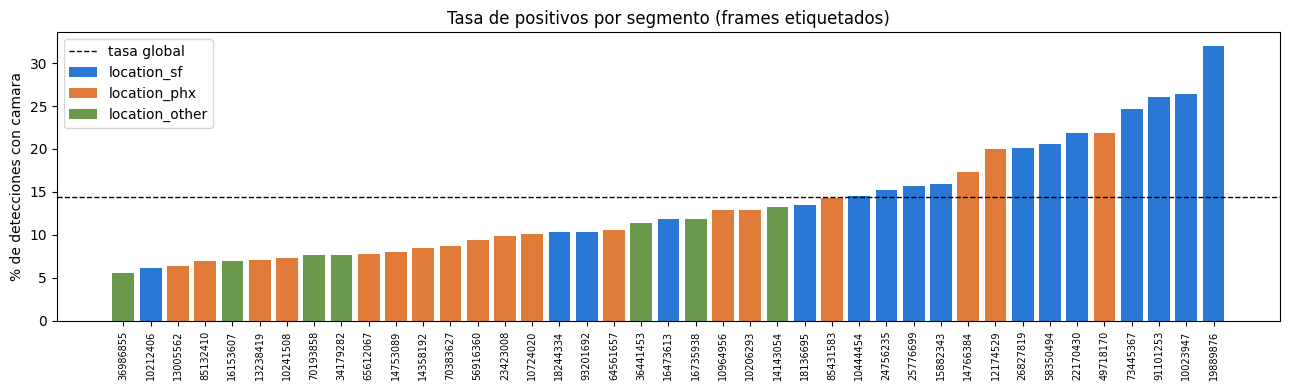

In [5]:
colores = {"location_sf": "#2a78d6", "location_phx": "#e07b39", "location_other": "#6a994e"}
orden = seg.sort_values("tasa_pct")

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(range(len(orden)), orden["tasa_pct"], color=[colores[l] for l in orden["location"]])
ax.axhline(df["tiene_camara"].mean() * 100, color="k", ls="--", lw=1, label="tasa global")
ax.set_xticks(range(len(orden)))
ax.set_xticklabels([s[:8] for s in orden["segment_id"]], rotation=90, fontsize=7)
ax.set_ylabel("% de detecciones con camara")
ax.set_title("Tasa de positivos por segmento (frames etiquetados)")
for loc, c in colores.items():
    ax.bar(0, 0, color=c, label=loc)
ax.legend()
fig.tight_layout()
guardar_fig(fig, "06_tasa_por_segmento")
plt.show()

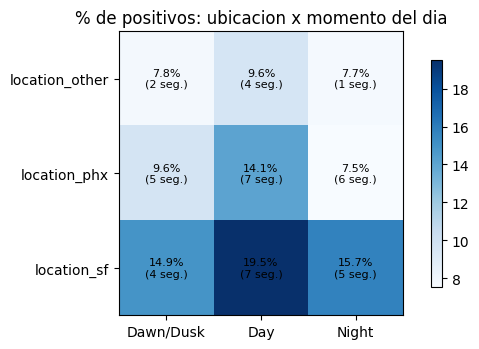

Tasa por ubicacion (ponderada por filas):
location
location_other     8.7
location_phx      10.0
location_sf       17.3

Tasa por momento del dia (ponderada por filas):
time_of_day
Dawn/Dusk    12.7
Day          17.0
Night        12.0


In [6]:
tabla = df.groupby(["location", "time_of_day"])["tiene_camara"].mean().unstack() * 100
n_seg = seg.groupby(["location", "time_of_day"]).size().unstack()

fig, ax = plt.subplots(figsize=(6, 3.6))
im = ax.imshow(tabla.values, cmap="Blues")
ax.set_xticks(range(len(tabla.columns)), tabla.columns)
ax.set_yticks(range(len(tabla.index)), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        if np.isnan(tabla.values[i, j]):
            ax.text(j, i, "sin\nsegmentos", ha="center", va="center", fontsize=8, color="gray")
        else:
            ax.text(j, i, f"{tabla.values[i, j]:.1f}%\n({int(n_seg.values[i, j])} seg.)", ha="center", va="center", fontsize=8)
ax.set_title("% de positivos: ubicacion x momento del dia")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
guardar_fig(fig, "06_heatmap_ubicacion_hora")
plt.show()

print("Tasa por ubicacion (ponderada por filas):")
print((df.groupby("location")["tiene_camara"].mean() * 100).round(1).to_string())
print("\nTasa por momento del dia (ponderada por filas):")
print((df.groupby("time_of_day")["tiene_camara"].mean() * 100).round(1).to_string())

**Lectura.** *(Completar tras ejecutar.)* ¿La ubicación explica más diferencia que el
momento del día? Dentro de cada ciudad, ¿la noche tiene menos positivos que el día?
Esto justifica (a) no usar `location` ni `time_of_day` como variables y (b) reportar el
KPI de equidad Day vs Night **dentro de cada ubicación**.

## A.5 Clases de objeto

              filas  positivos  segmentos  pct_de_filas  tasa_pct
object_type                                                      
VEHICLE      204514          0         41         44.74       0.0
PEDESTRIAN   130472      63872         40         28.55      49.0
SIGN         119481          0         41         26.14       0.0
CYCLIST        2603       1718         15          0.57      66.0


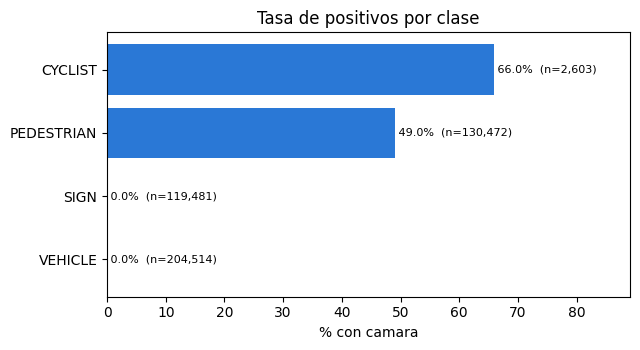


CYCLIST aparece en 15 de 41 segmentos.


In [7]:
clases = df.groupby("object_type").agg(filas=("tiene_camara", "size"), positivos=("tiene_camara", "sum"),
                                       segmentos=("segment_id", "nunique"))
clases["pct_de_filas"] = (clases["filas"] / clases["filas"].sum() * 100).round(2)
clases["tasa_pct"] = (clases["positivos"] / clases["filas"] * 100).round(1)
print(clases.sort_values("filas", ascending=False))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
c = clases.sort_values("tasa_pct")
ax.barh(c.index, c["tasa_pct"], color="#2a78d6")
for i, (t, n) in enumerate(zip(c["tasa_pct"], c["filas"])):
    ax.text(t, i, f" {t:.1f}%  (n={n:,})", va="center", fontsize=8)
ax.set_xlabel("% con camara")
ax.set_title("Tasa de positivos por clase")
ax.set_xlim(0, c["tasa_pct"].max() * 1.35)
fig.tight_layout()
guardar_fig(fig, "06_tasa_por_clase")
plt.show()

print(f"\nCYCLIST aparece en {int((seg['ciclistas'] > 0).sum())} de {len(seg)} segmentos.")

**Lectura.** *(Completar.)* ¿Hay clases con tasas muy distintas (p. ej. `SIGN`, estático,
frente a `VEHICLE`)? Los `CYCLIST` son pocos y están concentrados en pocos segmentos:
el split y las métricas por clase deben tratarse con cautela.

## A.6 Geometría: distancia y ángulo respecto del auto

Hipótesis: las cámaras del auto cubren el frente y los costados, no la parte trasera ni
objetos muy lejanos. Si es así, **la probabilidad de tener cámara depende de dónde está
el objeto** (distancia y ángulo), más que de su tamaño o de cuántos puntos LiDAR tiene.

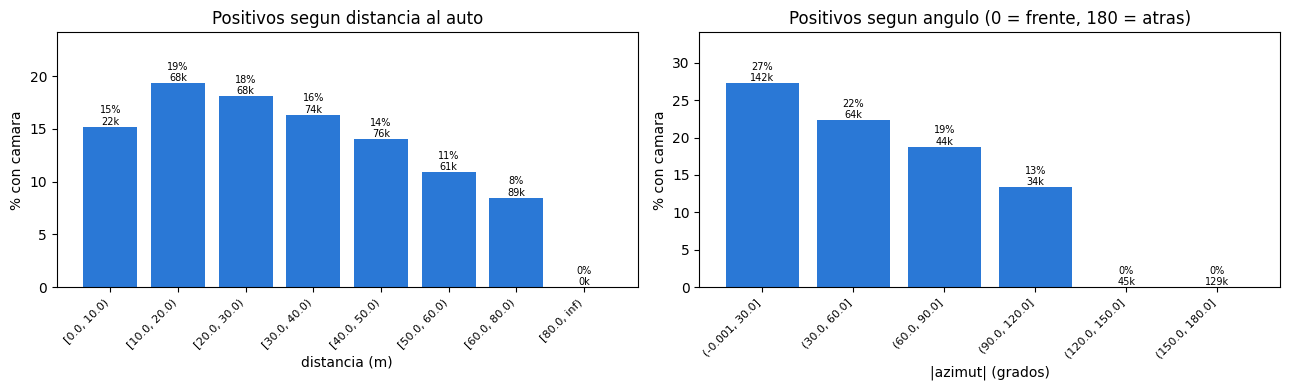

In [8]:
def tasa_por_bins(bins, datos=df):
    g = datos.groupby(bins, observed=True)["tiene_camara"].agg(filas="size", tasa="mean")
    g["tasa"] = g["tasa"] * 100
    return g


def barras(ax, g, titulo, xlabel):
    ax.bar(range(len(g)), g["tasa"], color="#2a78d6")
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=8)
    for i, (t, n) in enumerate(zip(g["tasa"], g["filas"])):
        ax.text(i, t, f"{t:.0f}%\n{n / 1000:.0f}k", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, g["tasa"].max() * 1.25)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% con camara")


g_dist = tasa_por_bins(pd.cut(df["distancia_m"], [0, 10, 20, 30, 40, 50, 60, 80, np.inf], right=False))
g_azim = tasa_por_bins(pd.cut(df["azimut_abs_deg"], np.arange(0, 181, 30), include_lowest=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
barras(axes[0], g_dist, "Positivos segun distancia al auto", "distancia (m)")
barras(axes[1], g_azim, "Positivos segun angulo (0 = frente, 180 = atras)", "|azimut| (grados)")
fig.tight_layout()
guardar_fig(fig, "06_tasa_por_distancia_azimut")
plt.show()

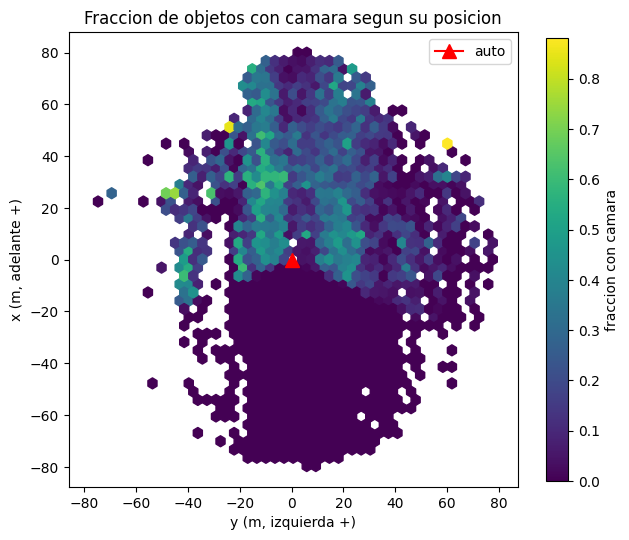

In [9]:
# Mapa de cobertura: vista desde arriba, color = % de positivos. El auto esta en (0, 0).
muestra = df.sample(min(150_000, len(df)), random_state=SEMILLA)
m = muestra[(muestra["box_center_x"].abs() < 80) & (muestra["box_center_y"].abs() < 80)]

fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(m["box_center_y"], m["box_center_x"], C=m["tiene_camara"], reduce_C_function=np.mean,
               gridsize=45, cmap="viridis", mincnt=20)
ax.plot(0, 0, marker="^", color="red", ms=10, label="auto")
ax.set_xlabel("y (m, izquierda +)")
ax.set_ylabel("x (m, adelante +)")
ax.set_title("Fraccion de objetos con camara segun su posicion")
ax.set_aspect("equal")
ax.legend(loc="upper right")
fig.colorbar(hb, ax=ax, shrink=0.8, label="fraccion con camara")
fig.tight_layout()
guardar_fig(fig, "06_mapa_cobertura_camara")
plt.show()

**Lectura.** *(Completar.)* Si el mapa muestra zonas casi sin positivos (p. ej. detrás
del auto), la cobertura geométrica de las cámaras es el principal determinante del target:
`distancia_m` y `azimut_abs_deg` deben ser variables centrales del modelo, y esto explica
por qué el tamaño o los puntos LiDAR correlacionaron débilmente en EP1.

## A.7 Puntos LiDAR y tamaño de la caja

En EP1 la hipótesis inicial era que `num_lidar_points` sería la variable más informativa
y no se sostuvo (Pearson −0,09, Spearman +0,09). Se revisa con la muestra ampliada.

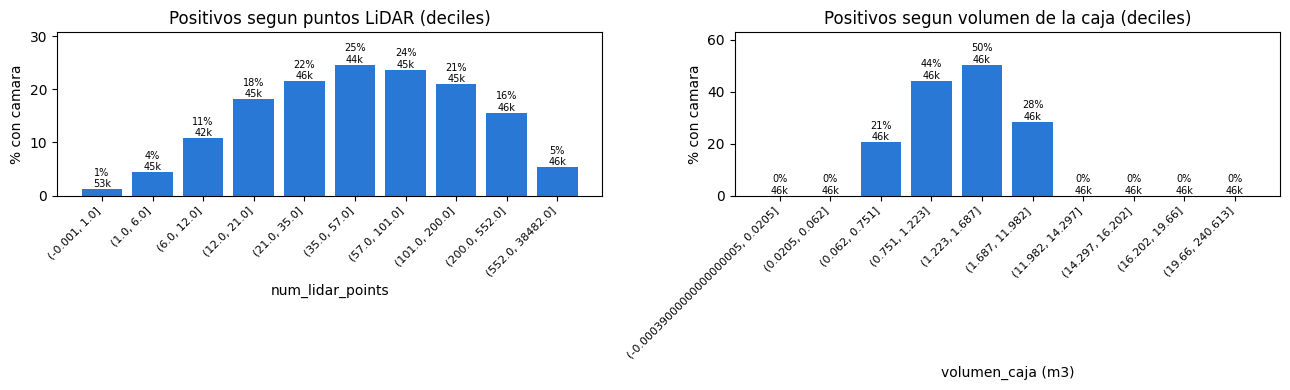

In [10]:
g_pts = tasa_por_bins(pd.qcut(df["num_lidar_points"], 10, duplicates="drop"))
g_vol = tasa_por_bins(pd.qcut(df["volumen_caja"], 10, duplicates="drop"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
barras(axes[0], g_pts, "Positivos segun puntos LiDAR (deciles)", "num_lidar_points")
barras(axes[1], g_vol, "Positivos segun volumen de la caja (deciles)", "volumen_caja (m3)")
fig.tight_layout()
guardar_fig(fig, "06_tasa_por_puntos_volumen")
plt.show()

## A.8 Correlaciones, asimetría y redundancia entre variables

Relacion de cada variable con tiene_camara (muestra de 150.000 filas):
                      pearson  spearman  asimetria
azimut_abs_deg         -0.332    -0.309      0.138
box_center_x            0.282     0.287     -0.155
speed_mps               0.011     0.265      3.984
box_height              0.184     0.207     -0.051
box_width              -0.278    -0.189      0.212
box_center_z           -0.179    -0.162      0.898
densidad_puntos        -0.067     0.126     13.530
box_length             -0.281    -0.125      0.536
volumen_caja           -0.233    -0.125      5.642
distancia_m            -0.105    -0.105      0.113
num_lidar_points       -0.070     0.102     10.457
num_top_lidar_points   -0.070     0.101     11.071
box_center_y           -0.064    -0.068      0.362
heading_cos            -0.033    -0.037     -0.077
heading_sin            -0.004    -0.007      0.000


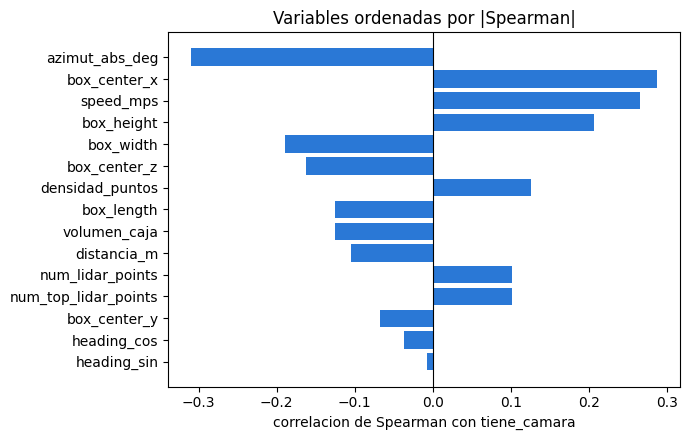

In [11]:
NUM_EDA = ["distancia_m", "azimut_abs_deg", "box_center_x", "box_center_y", "box_center_z",
           "box_length", "box_width", "box_height", "volumen_caja", "num_lidar_points",
           "num_top_lidar_points", "densidad_puntos", "speed_mps", "heading_sin", "heading_cos"]

corr = pd.DataFrame({
    "pearson": muestra[NUM_EDA].corrwith(muestra["tiene_camara"]),
    "spearman": muestra[NUM_EDA].corrwith(muestra["tiene_camara"], method="spearman"),
    "asimetria": df[NUM_EDA].skew(),
}).round(3)
corr = corr.reindex(corr["spearman"].abs().sort_values(ascending=False).index)
print("Relacion de cada variable con tiene_camara (muestra de 150.000 filas):")
print(corr)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(corr.index[::-1], corr["spearman"][::-1], color="#2a78d6")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("correlacion de Spearman con tiene_camara")
ax.set_title("Variables ordenadas por |Spearman|")
fig.tight_layout()
guardar_fig(fig, "06_correlacion_con_target")
plt.show()

In [12]:
# Pares de variables muy redundantes (|Spearman| > 0.9): candidatas a revisar en modelos lineales.
mc = muestra[NUM_EDA].corr(method="spearman").abs()
pares = [(a, b, round(mc.loc[a, b], 2)) for i, a in enumerate(NUM_EDA) for b in NUM_EDA[i + 1:] if mc.loc[a, b] > 0.9]
print("Pares con |Spearman| > 0.9:")
for a, b, v in pares:
    print(f"  {a} <-> {b}: {v}")
if not pares:
    print("  (ninguno)")

Pares con |Spearman| > 0.9:
  azimut_abs_deg <-> box_center_x: 0.93
  box_length <-> box_width: 0.93
  box_length <-> volumen_caja: 0.98
  box_width <-> volumen_caja: 0.95
  num_lidar_points <-> num_top_lidar_points: 1.0


**Lectura.** *(Completar.)* ¿Qué variables tienen mayor |Spearman|? Una asimetría alta
(p. ej. `num_lidar_points`, `densidad_puntos`, `volumen_caja`) justifica aplicar
`log1p` en el modelo lineal; los árboles no la necesitan. Los pares redundantes importan
para interpretar coeficientes de la regresión logística.

## A.9 Lluvia vs soleado (solo descriptivo)

Los 5 segmentos de lluvia no tienen target confiable, pero sus variables de entrada sí se
pueden comparar. Son segmentos chicos (cientos a pocos miles de detecciones): sirve para
describir, no para concluir.

In [13]:
cols_comp = ["distancia_m", "num_lidar_points", "volumen_caja", "speed_mps"]
comp = completo.groupby("weather").agg(
    segmentos=("segment_id", "nunique"), filas=("segment_id", "size"),
    **{f"mediana_{c}": (c, "median") for c in cols_comp},
).round(2)
print(comp)

print("\nComposicion por clase (% de filas):")
print((pd.crosstab(completo["weather"], completo["object_type"], normalize="index") * 100).round(1))

print("\nTamano de cada segmento de lluvia:")
print(completo[completo["weather"] == "rain"].groupby(["segment_id", "time_of_day", "location"]).size().rename("filas"))

         segmentos   filas  mediana_distancia_m  mediana_num_lidar_points  mediana_volumen_caja  mediana_speed_mps
weather                                                                                                           
rain             5   11196                49.81                      39.0                 12.76               0.23
sunny           41  489613                39.61                      35.0                  1.74               0.01

Composicion por clase (% de filas):
object_type  CYCLIST  PEDESTRIAN  SIGN  VEHICLE
weather                                        
rain             0.0         1.5  38.2     60.3
sunny            0.6        27.3  26.4     45.7

Tamano de cada segmento de lluvia:
segment_id                              time_of_day  location    
13830510593707564159_5575_000_5595_000  Dawn/Dusk    location_phx    1263
16511546224219511043_6226_000_6246_000  Dawn/Dusk    location_phx     986
2974991090366925955_4924_000_4944_000   Dawn/Dusk    location

**Lectura.** *(Completar.)* Los segmentos de lluvia son muy pequeños y de escenas poco
cargadas, así que cualquier diferencia puede venir de la escena y no del clima. Por eso
la lluvia queda como limitación documentada y como insumo del clustering, no como
variable del modelo.

## A.10 Conclusiones del EDA y decisiones para la preparación

*(Ajustar con lo observado al ejecutar.)*

1. **Calidad:** sin nulos ni valores imposibles relevantes en las variables de entrada
   (ver A.2); el problema de calidad de los datos reales está en el **etiquetado**
   (frames sin etiquetas), ya tratado con el filtro de frames.
2. **Target:** desbalance moderado (~14 %). La tasa depende fuertemente de la
   **ubicación** y algo de la hora del día.
3. **Variables:** la posición (distancia y ángulo) captura la cobertura de las cámaras;
   se agregan `azimut_abs_deg`, `heading_sin` y `heading_cos` como variables derivadas.
4. **Transformaciones:** `log1p` para variables muy asimétricas en el modelo lineal.
5. **Sesgos a documentar:** muestra condicionada a segmentos con etiquetado denso,
   sobrerrepresentación de noche y amanecer/atardecer, lluvia sin target.

# PARTE B — Preparación para modelamiento (*Data Preparation*)

## B.1 Variables del modelo y exclusiones

La regla es: **solo atributos conocidos en el momento de la detección LiDAR**, sin
nada que provenga de la cámara, del target o del proceso de etiquetado.

In [14]:
FEATURES_NUM = [
    "box_center_x", "box_center_y", "box_center_z", "azimut_abs_deg", "distancia_m",
    "box_length", "box_width", "box_height", "volumen_caja",
    "num_lidar_points", "num_top_lidar_points", "densidad_puntos",
    "speed_mps", "heading_sin", "heading_cos",
]
FEATURES_CAT = ["object_type"]
TARGET = "tiene_camara"
GRUPO = "segment_id"
COLS_EVALUACION = ["time_of_day", "location"]                       # solo para evaluar equidad
COLS_IDENT = ["key.frame_timestamp_micros", "key.laser_object_id"]  # trazabilidad, NO son features

exclusiones = pd.DataFrame([
    ("key.* (ids de segmento, frame y objeto)", "Identificadores: permitirian memorizar objetos y frames."),
    ("segment_id", "Es el grupo del split; no es una variable."),
    ("weather", "Decision EP2: sin varianza util (99,4 % soleado) y sin segmentos de lluvia con etiquetas confiables."),
    ("location, time_of_day", "Metadatos del segmento: serian un atajo por ciudad/hora y no transferirian a otros paises. Solo para evaluar."),
    ("uso, frame_etiquetado", "Derivadas del proceso de etiquetado y del target (fuga)."),
    ("[LiDARBoxComponent].difficulty_level.*", "Se calcula a partir de los puntos LiDAR: redundante con num_lidar_points."),
    ("speed.z, acceleration.x/y/z", "Ruidosas y de baja relevancia a priori; se pueden probar en una ablacion."),
    ("[LiDARBoxComponent].* (columnas crudas)", "Duplicadas por las columnas estandar (box_*, num_lidar_points, object_type)."),
], columns=["excluida", "motivo"])
print(exclusiones.to_string(index=False))

# Controles anti-fuga
prohibidas = ("camara", "camera", "asoc", "tiene_camara", "frame_etiquetado", "weather", "location", "time_of_day")
assert not [f for f in FEATURES_NUM + FEATURES_CAT if any(p in f.lower() for p in prohibidas)], "Feature sospechosa de fuga"
faltantes = [c for c in FEATURES_NUM + FEATURES_CAT + [TARGET, GRUPO, *COLS_EVALUACION, *COLS_IDENT] if c not in df.columns]
assert not faltantes, f"Faltan columnas: {faltantes}"
sospechosas = df[FEATURES_NUM].corrwith(df[TARGET]).abs()
print(f"\nMayor |Pearson| de una variable con el target: {sospechosas.max():.2f} ({sospechosas.idxmax()}) "
      "-> un valor cercano a 1 indicaria fuga.")
print(f"\nNulos en variables numericas:\n{df[FEATURES_NUM].isna().sum()[lambda s: s > 0].to_string() or '(ninguno)'}")

                               excluida                                                                                                        motivo
key.* (ids de segmento, frame y objeto)                                                      Identificadores: permitirian memorizar objetos y frames.
                             segment_id                                                                    Es el grupo del split; no es una variable.
                                weather          Decision EP2: sin varianza util (99,4 % soleado) y sin segmentos de lluvia con etiquetas confiables.
                  location, time_of_day Metadatos del segmento: serian un atajo por ciudad/hora y no transferirian a otros paises. Solo para evaluar.
                  uso, frame_etiquetado                                                      Derivadas del proceso de etiquetado y del target (fuga).
 [LiDARBoxComponent].difficulty_level.*                                     Se calcula a partir de l

**Tratamiento de nulos y escalas:** se difiere al pipeline de modelamiento (notebook 09)
para ajustarlo **solo con train** y evitar fuga: imputación por mediana, `log1p` en las
variables asimétricas y estandarización para la regresión logística; los árboles usan las
variables sin transformar. `object_type` se codifica con *one-hot* (4 categorías).

## B.2 Split por segmento

**Por qué por segmento:** los objetos y frames de un mismo segmento son casi idénticos
entre sí. Si el split fuera por fila, el modelo vería en train objetos casi iguales a los de
test y las métricas saldrían infladas. La unidad independiente es el segmento.

**Cómo:** se reservan ~20 % de los segmentos para test. Entre 1.000 combinaciones
reproducibles se elige la que cumple condiciones de representatividad (todas las
ubicaciones y momentos del día, al menos 2 segmentos con ciclistas, 15–25 % de las filas)
y deja la tasa de positivos más parecida a la global.

**El test no se vuelve a tocar hasta el notebook 10.**

In [15]:
N_TEST = int(round(0.20 * len(seg)))
total_filas = seg["filas"].sum()
tasa_global = seg["positivos"].sum() / total_filas

mejor = None
for semilla in range(1000):
    ids = np.random.RandomState(semilla).choice(seg["segment_id"].values, size=N_TEST, replace=False)
    t = seg[seg["segment_id"].isin(ids)]
    if t["location"].nunique() < seg["location"].nunique() or t["time_of_day"].nunique() < seg["time_of_day"].nunique():
        continue
    if (t["ciclistas"] > 0).sum() < 2:
        continue
    fraccion = t["filas"].sum() / total_filas
    if not 0.15 <= fraccion <= 0.25:
        continue
    desvio = abs(t["positivos"].sum() / t["filas"].sum() - tasa_global) * 100 + abs(fraccion - 0.20) * 100
    if mejor is None or desvio < mejor[0]:
        mejor = (desvio, semilla, sorted(ids))

if mejor is None:
    raise RuntimeError("Ninguna combinacion cumple las condiciones: relajarlas.")
desvio, semilla_split, ids_test = mejor
seg["conjunto"] = np.where(seg["segment_id"].isin(ids_test), "test", "train")

print(f"Semilla elegida: {semilla_split} (desvio {desvio:.2f}) | segmentos test: {len(ids_test)} de {len(seg)}")
resumen_split = seg.groupby("conjunto").agg(
    segmentos=("segment_id", "count"), filas=("filas", "sum"), positivos=("positivos", "sum"), ciclistas=("ciclistas", "sum"))
resumen_split["tasa_pct"] = (resumen_split["positivos"] / resumen_split["filas"] * 100).round(2)
resumen_split["pct_filas"] = (resumen_split["filas"] / total_filas * 100).round(1)
print(resumen_split)
print("\nComposicion de los segmentos de test:")
print(pd.crosstab(seg.loc[seg["conjunto"] == "test", "location"], seg.loc[seg["conjunto"] == "test", "time_of_day"], margins=True))

Semilla elegida: 934 (desvio 0.26) | segmentos test: 8 de 41
          segmentos   filas  positivos  ciclistas  tasa_pct  pct_filas
conjunto                                                              
test              8   90756      12919        498     14.23       19.9
train            33  366314      52671       2105     14.38       80.1

Composicion de los segmentos de test:
time_of_day     Dawn/Dusk  Day  Night  All
location                                  
location_other          0    2      0    2
location_phx            0    3      0    3
location_sf             1    1      1    3
All                     1    6      1    8


## B.3 Validación cruzada agrupada dentro de train

Para elegir hiperparámetros se usa `StratifiedGroupKFold` (5 folds): mantiene juntos los
segmentos y reparte los positivos de forma parecida. El número de fold queda guardado en
cada fila, de modo que todos los modelos usen **exactamente los mismos folds**.

In [16]:
from sklearn.model_selection import StratifiedGroupKFold

cols_guardar = [GRUPO, *COLS_IDENT, *COLS_EVALUACION, *FEATURES_NUM, *FEATURES_CAT, TARGET]
train = df[~df[GRUPO].isin(ids_test)][cols_guardar].reset_index(drop=True)
test = df[df[GRUPO].isin(ids_test)][cols_guardar].reset_index(drop=True)

train["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for k, (_, idx_val) in enumerate(sgkf.split(train, train[TARGET], groups=train[GRUPO])):
    train.loc[idx_val, "fold"] = k

folds = train.groupby("fold").agg(
    segmentos=(GRUPO, "nunique"), filas=(TARGET, "size"), tasa_pct=(TARGET, lambda s: round(s.mean() * 100, 2)),
    ciclistas=("object_type", lambda s: int((s == "CYCLIST").sum())),
)
folds["segmentos_noche"] = (
    train[train["time_of_day"] == "Night"].groupby("fold")[GRUPO].nunique().reindex(folds.index).fillna(0).astype(int)
)
print(folds)

# Controles de integridad del split
assert set(train[GRUPO]).isdisjoint(set(test[GRUPO])), "Hay segmentos en train y test"
for k in range(5):
    assert set(train.loc[train["fold"] == k, GRUPO]).isdisjoint(set(train.loc[train["fold"] != k, GRUPO])), f"Fold {k} comparte segmentos"
assert (train["fold"] >= 0).all()
print("\nControles OK: ningun segmento aparece en dos conjuntos ni en dos folds.")
if (folds["ciclistas"] == 0).any():
    print("ATENCION: algun fold no tiene ciclistas; las metricas por clase de CYCLIST seran inestables.")

      segmentos  filas  tasa_pct  ciclistas  segmentos_noche
fold                                                        
0             5  52400      9.99        522                1
1             7  40199     19.26        482                3
2             7  99606     11.76          0                4
3             8  97163     14.97        827                1
4             6  76946     17.46        274                2

Controles OK: ningun segmento aparece en dos conjuntos ni en dos folds.
ATENCION: algun fold no tiene ciclistas; las metricas por clase de CYCLIST seran inestables.


## B.4 Desbalance de clases y línea base

Con ~14 % de positivos el desbalance es moderado. Se aborda con **pesos de clase** y
**ajuste del umbral de decisión**, no con SMOTE: interpolar cajas 3D entre objetos
distintos produce observaciones que no existen (y el sobremuestreo antes del split filtra
información). SMOTE queda como comparación opcional, aplicado solo dentro de cada fold.

Una predicción constante ("nunca hay cámara") ya tiene alta exactitud, por eso las
métricas del proyecto son **Recall, F1, AUC-ROC y PR-AUC**, no la exactitud.

In [17]:
n_pos, n_neg = int(train[TARGET].sum()), int((train[TARGET] == 0).sum())
print(f"Train: {n_pos:,} positivos y {n_neg:,} negativos ({n_pos / (n_pos + n_neg):.2%} positivos)")
print(f"Peso sugerido (class_weight='balanced'): clase 0 = {(n_pos + n_neg) / (2 * n_neg):.2f} | clase 1 = {(n_pos + n_neg) / (2 * n_pos):.2f}")
print(f"scale_pos_weight para XGBoost: {n_neg / n_pos:.2f}")

mayoritaria_acc = n_neg / (n_pos + n_neg)
print(f"\nBaseline 'siempre 0': exactitud {mayoritaria_acc:.1%}, recall 0.0, F1 0.0, AUC-ROC 0.5 -> la exactitud no sirve.")

Train: 52,671 positivos y 313,643 negativos (14.38% positivos)
Peso sugerido (class_weight='balanced'): clase 0 = 0.58 | clase 1 = 3.48
scale_pos_weight para XGBoost: 5.95

Baseline 'siempre 0': exactitud 85.6%, recall 0.0, F1 0.0, AUC-ROC 0.5 -> la exactitud no sirve.


## B.5 Guardado de los conjuntos

In [18]:
train.to_parquet(RUTA_MODEL_INPUT / "train.parquet", index=False)
test.to_parquet(RUTA_MODEL_INPUT / "test.parquet", index=False)
seg[["segment_id", "location", "time_of_day", "filas", "positivos", "ciclistas", "conjunto"]].merge(
    train[[GRUPO, "fold"]].drop_duplicates(), on=GRUPO, how="left"
).to_csv(RUTA_MODEL_INPUT / "split_segmentos.csv", index=False)   # conserva segment_id (antes se perdia por un drop)

config = {
    "target": TARGET, "grupo": GRUPO, "features_num": FEATURES_NUM, "features_cat": FEATURES_CAT,
    "cols_evaluacion": COLS_EVALUACION, "cols_ident": COLS_IDENT,
    "n_folds": 5, "semilla": SEMILLA, "semilla_split_test": int(semilla_split),
    "segmentos_test": ids_test,
    "kpis": {"recall_min": 0.85, "f1_min": 0.80, "auc_roc_min": 0.85, "brecha_equidad_max_pp": 10},
}
(RUTA_MODEL_INPUT / "config_features.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

for archivo in ["train.parquet", "test.parquet", "split_segmentos.csv", "config_features.json"]:
    print(f"{archivo:24s} {(RUTA_MODEL_INPUT / archivo).stat().st_size / 1e6:7.2f} MB")

train.parquet              32.04 MB
test.parquet                8.99 MB
split_segmentos.csv         0.00 MB
config_features.json        0.00 MB


## B.6 Resumen de la preparación

| Elemento | Decisión |
|---|---|
| Datos | `waymo_supervisado`: 41 segmentos, frames etiquetados |
| Variables | 15 numéricas (posición, tamaño, puntos LiDAR, velocidad, orientación) + `object_type` |
| Excluidas | ids, `weather`, `location`, `time_of_day`, `uso`, `frame_etiquetado`, `difficulty_level` |
| Split | ~20 % de los segmentos a test; validación cruzada agrupada de 5 folds en train |
| Desbalance | `class_weight` / `scale_pos_weight` + ajuste de umbral (SMOTE opcional) |
| Métricas | Recall, F1, AUC-ROC, PR-AUC; equidad por ubicación × momento del día |

**Siguiente paso, un notebook por número:** el 07 justifica la elección del target y la compara con las
otras opciones; el 08 analiza los datos del target elegido; el 09 entrena los modelos supervisados
(regresión logística como línea base interpretable y un modelo de árboles potenciado) sobre `train.parquet`
con los folds ya definidos; el 10 evalúa en el test y cierra.

In [19]:
# --- (a) Tasa de positivos SOLO entre peatones y ciclistas
pc = df[df["object_type"].isin(["PEDESTRIAN", "CYCLIST"])]
resto = df[~df["object_type"].isin(["PEDESTRIAN", "CYCLIST"])]
print(f"Peatones + ciclistas: {len(pc):,} filas ({len(pc) / len(df):.1%}) | positivos {int(pc['tiene_camara'].sum()):,} ({pc['tiene_camara'].mean():.1%})")
print(f"Vehiculos + senales:  {len(resto):,} filas ({len(resto) / len(df):.1%}) | positivos {int(resto['tiene_camara'].sum()):,}")
print("\nTasa (%) entre peatones/ciclistas, por ubicacion x momento del dia:")
print((pc.groupby(["location", "time_of_day"])["tiene_camara"].mean().unstack() * 100).round(1))
print("\nFilas de peatones/ciclistas por ubicacion x momento del dia:")
print(pc.groupby(["location", "time_of_day"]).size().unstack())
print("\nTasa (%) entre peatones/ciclistas por segmento (distribucion):")
print((pc.groupby("segment_id")["tiene_camara"].mean() * 100).describe().round(1).to_string())

# --- (b) Segmentos rechazados, vistos con la cantidad de peatones/ciclistas que tienen
docs = RAIZ / "docs" / "seleccion_segmentos"
inv = pd.read_csv(docs / "inventario_segmentos.csv").set_index("segment_id")
inv["ped_cyc"] = inv["PEDESTRIAN"] + inv["CYCLIST"]
reg = pd.read_csv(docs / "registro_verificacion_ep2.csv").merge(inv[["ped_cyc"]], left_on="segment_id", right_index=True)
motivo = reg["motivo"].fillna("")
reg["grupo"] = np.select([reg["resultado"].eq("seleccionado"), motivo.str.contains("vacia"), motivo.str.contains("ralo")],
                         ["seleccionado", "asociacion vacia", "etiquetado ralo"], default="otro")
reg["positivos_sobre_ped_cyc"] = reg["positivos"] / reg["ped_cyc"].where(reg["ped_cyc"] > 0)
print("\nSegmentos evaluados, segun cuantos peatones+ciclistas tienen:")
print(reg.groupby("grupo").agg(
    segmentos=("segment_id", "size"),
    sin_peatones_ni_ciclistas=("ped_cyc", lambda s: int((s == 0).sum())),
    mediana_ped_cyc=("ped_cyc", "median"),
    mediana_positivos_sobre_ped_cyc=("positivos_sobre_ped_cyc", "median"),
).round(2).to_string())
print("\nDetalle de los rechazados por etiquetado ralo:")
print(reg.loc[reg["grupo"] == "etiquetado ralo", ["segment_id", "time_of_day", "location", "ped_cyc", "positivos", "positivos_sobre_ped_cyc"]].round(2).to_string(index=False))

# --- (c) Segmentos de lluvia
ll = pd.read_csv(docs / "diagnostico_lluvia_ep2.csv").merge(inv[["PEDESTRIAN", "CYCLIST"]], left_on="segment_id", right_index=True)
print("\nSegmentos de lluvia:")
print(ll[["segment_id", "time_of_day", "location", "asoc_filas", "positivos", "PEDESTRIAN", "CYCLIST"]].to_string(index=False))

Peatones + ciclistas: 133,075 filas (29.1%) | positivos 65,590 (49.3%)
Vehiculos + senales:  323,995 filas (70.9%) | positivos 0

Tasa (%) entre peatones/ciclistas, por ubicacion x momento del dia:
time_of_day     Dawn/Dusk   Day  Night
location                              
location_other       59.3  72.5   71.4
location_phx         72.2  64.4   62.1
location_sf          62.8  46.3   36.6

Filas de peatones/ciclistas por ubicacion x momento del dia:
time_of_day     Dawn/Dusk    Day  Night
location                               
location_other       2817   4028   1094
location_phx         1883   8436   7304
location_sf         15421  56327  35765

Tasa (%) entre peatones/ciclistas por segmento (distribucion):
count    41.0
mean     64.5
std      18.9
min      27.7
25%      52.6
50%      62.8
75%      72.5
max      98.7

Segmentos evaluados, segun cuantos peatones+ciclistas tienen:
                  segmentos  sin_peatones_ni_ciclistas  mediana_ped_cyc  mediana_positivos_sobre_ped_cyc
g

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, recall_score, f1_score

train = pd.read_parquet(RUTA_MODEL_INPUT / "train.parquet")
pc = train[train["object_type"].isin(["PEDESTRIAN", "CYCLIST"])].reset_index(drop=True)
pc["es_ciclista"] = (pc["object_type"] == "CYCLIST").astype(int)

GEOMETRIA = ["box_center_x", "box_center_y", "azimut_abs_deg", "distancia_m"]
conjuntos = {
    "solo la clase": ["es_ciclista"],
    "solo geometria (posicion)": GEOMETRIA + ["es_ciclista"],
    "todas las variables": FEATURES_NUM + ["es_ciclista"],
}
en_zona = pc["azimut_abs_deg"] <= 120      # zona que las camaras alcanzan a cubrir
print(f"Peatones+ciclistas en train: {len(pc):,} | positivos {pc[TARGET].mean():.1%} | "
      f"dentro de la zona de camaras: {en_zona.mean():.1%} de las filas, {pc.loc[en_zona, TARGET].mean():.1%} positivos")

filas = []
for nombre, cols in conjuntos.items():
    oof = np.zeros(len(pc))
    for k in sorted(pc["fold"].unique()):
        tr, va = pc["fold"] != k, pc["fold"] == k
        modelo = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA)
        modelo.fit(pc.loc[tr, cols], pc.loc[tr, TARGET])
        oof[va.values] = modelo.predict_proba(pc.loc[va, cols])[:, 1]
    pred = oof >= 0.5
    filas.append({
        "variables": nombre,
        "AUC (todo)": roc_auc_score(pc[TARGET], oof),
        "AUC (solo zona de camaras)": roc_auc_score(pc.loc[en_zona, TARGET], oof[en_zona.values]),
        "Recall": recall_score(pc[TARGET], pred),
        "F1": f1_score(pc[TARGET], pred),
    })
print(pd.DataFrame(filas).round(3).to_string(index=False))

Peatones+ciclistas en train: 100,937 | positivos 52.2% | dentro de la zona de camaras: 67.9% de las filas, 76.8% positivos
                variables  AUC (todo)  AUC (solo zona de camaras)  Recall    F1
            solo la clase       0.387                       0.443   0.747 0.591
solo geometria (posicion)       0.881                       0.637   0.930 0.860
      todas las variables       0.950                       0.847   0.930 0.906


In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

train = pd.read_parquet(RUTA_MODEL_INPUT / "train.parquet")
vru = train[train["object_type"].isin(["PEDESTRIAN", "CYCLIST"])].reset_index(drop=True)
y = (vru["object_type"] == "CYCLIST").astype(int).values
print(f"Peatones+ciclistas en train: {len(vru):,} | ciclistas: {y.sum():,} ({y.mean():.2%}) en {vru.loc[y == 1, GRUPO].nunique()} segmentos")

oof = np.zeros(len(vru))
for k in sorted(vru["fold"].unique()):
    tr, va = (vru["fold"] != k).values, (vru["fold"] == k).values
    peso = np.where(y[tr] == 1, (1 - y[tr].mean()) / max(y[tr].mean(), 1e-9), 1.0)
    modelo = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA)
    modelo.fit(vru.loc[tr, FEATURES_NUM], y[tr], sample_weight=peso)
    oof[va] = modelo.predict_proba(vru.loc[va, FEATURES_NUM])[:, 1]

prec, rec, _ = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
i = f1[:-1].argmax()
ok = rec[:-1] >= 0.85
print(f"\nAUC-ROC: {roc_auc_score(y, oof):.3f} | PR-AUC: {average_precision_score(y, oof):.3f} (azar = {y.mean():.3f})")
print(f"Mejor F1 de ciclista: {f1[i]:.3f} (precision {prec[i]:.3f}, recall {rec[i]:.3f})")
print(f"Precision cuando se exige recall >= 0.85: {prec[:-1][ok].max() if ok.any() else float('nan'):.3f}")

pred = oof >= np.quantile(oof, 1 - y.mean())   # marca tantos ciclistas como los reales (referencia simple)

def resumen(mascara, nombre):
    yy, pp, ss = y[mascara], pred[mascara], oof[mascara]
    if yy.sum() < 20 or (1 - yy).sum() < 20:
        return {"grupo": nombre, "filas": int(mascara.sum()), "ciclistas": int(yy.sum()), "AUC": np.nan, "recall": np.nan, "precision": np.nan}
    return {"grupo": nombre, "filas": int(mascara.sum()), "ciclistas": int(yy.sum()), "AUC": roc_auc_score(yy, ss),
            "recall": (pp & (yy == 1)).sum() / yy.sum(), "precision": (pp & (yy == 1)).sum() / max(pp.sum(), 1)}

filas = []
for col in ["time_of_day", "location"]:
    for valor in sorted(vru[col].unique()):
        filas.append(resumen((vru[col] == valor).values, f"{col}={valor}"))
bins = pd.cut(vru["distancia_m"], [0, 10, 20, 30, 50, np.inf], right=False)
for b in bins.cat.categories:
    filas.append(resumen((bins == b).values, f"distancia {b}"))
print("\nRendimiento por condicion (grupos con menos de 20 ciclistas quedan en NaN):")
print(pd.DataFrame(filas).round(3).to_string(index=False))

Peatones+ciclistas en train: 100,937 | ciclistas: 2,105 (2.09%) en 12 segmentos

AUC-ROC: 0.988 | PR-AUC: 0.660 (azar = 0.021)
Mejor F1 de ciclista: 0.725 (precision 0.629, recall 0.856)
Precision cuando se exige recall >= 0.85: 0.629

Rendimiento por condicion (grupos con menos de 20 ciclistas quedan en NaN):
                  grupo  filas  ciclistas   AUC  recall  precision
  time_of_day=Dawn/Dusk  18933        727 0.990   0.596      0.606
        time_of_day=Day  46636       1005 0.993   0.687      0.558
      time_of_day=Night  35368        373 0.989   0.306      0.745
location=location_other   5696        627 0.993   0.522      0.838
  location=location_phx  13966        515 0.942   0.291      0.247
   location=location_sf  81275        963 0.998   0.789      0.687
  distancia [0.0, 10.0)   4254        221 0.977   0.548      0.738
 distancia [10.0, 20.0)  17400        323 0.988   0.619      0.625
 distancia [20.0, 30.0)  18072        327 0.989   0.670      0.499
 distancia [30.0, 

In [23]:
inv = pd.read_csv(RAIZ / "docs" / "seleccion_segmentos" / "inventario_segmentos.csv")
print(inv["CYCLIST"].describe().round(0).to_string())
for umbral in [200, 500, 1000]:
    print(f"Segmentos con >= {umbral} detecciones de ciclista: {(inv['CYCLIST'] >= umbral).sum()}")

count     798.0
mean       67.0
std       178.0
min         0.0
25%         0.0
50%         0.0
75%        49.0
max      1734.0
Segmentos con >= 200 detecciones de ciclista: 68
Segmentos con >= 500 detecciones de ciclista: 20
Segmentos con >= 1000 detecciones de ciclista: 6


In [24]:
H = 20  # 2 s a 10 Hz
vru = completo[completo["object_type"].isin(["PEDESTRIAN", "CYCLIST"])].copy()
vru = vru.sort_values(["segment_id", "key.laser_object_id", "key.frame_timestamp_micros"])
g = vru.groupby(["segment_id", "key.laser_object_id"])
vru["x_fut"] = g["box_center_x"].shift(-H)
vru["y_fut"] = g["box_center_y"].shift(-H)
vru["dt_fut"] = (g["key.frame_timestamp_micros"].shift(-H) - vru["key.frame_timestamp_micros"]) / 1e6

fut = vru[vru["dt_fut"].between(1.9, 2.1)]            # descarta tracks con huecos
en_corredor_ahora = fut["box_center_x"].between(0, 15) & (fut["box_center_y"].abs() < 2)
en_corredor_fut = fut["x_fut"].between(0, 15) & (fut["y_fut"].abs() < 2)
conflicto = en_corredor_fut & ~en_corredor_ahora

print(f"Detecciones con futuro a 2 s: {len(fut):,} de {len(vru):,}")
print(f"Conflictos nuevos a 2 s: {conflicto.sum():,} ({conflicto.mean():.2%}) "
      f"en {fut.loc[conflicto, 'segment_id'].nunique()} segmentos")
print(f"Objetos distintos en conflicto: "
      f"{fut.loc[conflicto, ['segment_id', 'key.laser_object_id']].drop_duplicates().shape[0]}")

Detecciones con futuro a 2 s: 113,442 de 136,398
Conflictos nuevos a 2 s: 68 (0.06%) en 2 segmentos
Objetos distintos en conflicto: 5
